l'objectif est de comprendre et justifier la sélection des variables finales de notre dataset. 
Nous allons comprendre le comportement de nos données et identifier celles pertinentes pour la modélisation.

Les variables que nous avons crées avaient pour but de capter plusieurs dimensions du marché :
le momentum, la volatilité, la tendance et la structure du marché. 

Toutes les variables créées ne seront pas nécessairement conservées.

L'objectif est de trouver un compromis entre :

- robustesse
- interprétabilité
- performances statistiques

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.feature_selection import mutual_info_classif

from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
FINAL_PATH = Path("../data/final")

df = pd.read_csv(FINAL_PATH / "BTCUSD_model_base.csv")

df["date"] = pd.to_datetime(df["date"])

print(df.shape)

df.head()

(4975, 30)


,symbol,date,open,high,low,close,volume,change,changePercent,vwap,...,rsi,BB_middle,BB_upper,BB_lower,BB_width,BB_percent,trend_signal,return_acceleration,future_return_5,target
0,BTCUSD,2012-05-07,5.05000,5.09569,4.97111,5.06002,0,0.01002,0.19842,5.04421,...,56.516697,5.088054,5.299120,4.876987,0.082965,0.433591,0,0.007338,-0.022496,-1
1,BTCUSD,2012-05-08,5.08738,5.10000,4.96000,5.04997,0,-0.03741,-0.73535,5.04934,...,46.226400,5.084662,5.295896,4.873428,0.083087,0.417882,0,-0.003988,-0.023764,-1
2,BTCUSD,2012-05-09,5.04988,5.09609,5.00000,5.04370,0,-0.00618,-0.12238,5.04742,...,42.800418,5.079964,5.290413,4.869515,0.082854,0.413841,0,0.000745,-0.007487,0
3,BTCUSD,2012-05-10,5.05970,5.12500,4.80284,4.85000,0,-0.20970,-4.14451,4.95938,...,33.951625,5.054964,5.248455,4.861473,0.076555,-0.029646,0,-0.037163,0.038144,1
4,BTCUSD,2012-05-11,4.85000,5.00000,4.80100,4.96000,0,0.11000,2.26804,4.90275,...,41.406115,5.039960,5.211809,4.868111,0.068195,0.267355,0,0.061085,0.025948,1


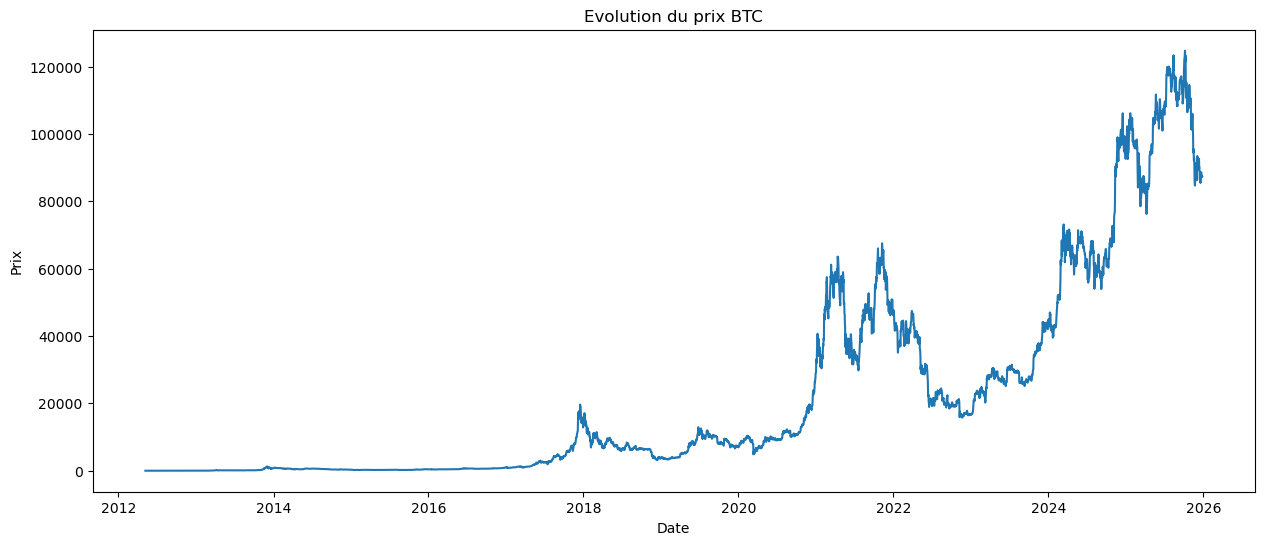

In [3]:

#Observation de l'évolution du BTC. 
# Nous voulons observer les marchés haussier, les marchés baissiers et les consolidations

plt.figure(figsize=(15,6))

plt.plot(df["date"],df["close"])

plt.title("Evolution du prix BTC")

plt.xlabel("Date")

plt.ylabel("Prix")

plt.show()

## Interprétation

Observations :

- Identifier les phases haussières majeures
- Identifier les marchés baissiers
- Observer les périodes de consolidation

Interprétation :

Le Bitcoin ne suit pas une dynamique stationnaire.
Le marché évolue selon plusieurs régimes :

- phases haussières
- phases baissières
- périodes de transition

Conséquence :

Les variables utilisées devront être suffisamment robustes pour fonctionner dans plusieurs environnements de marché.

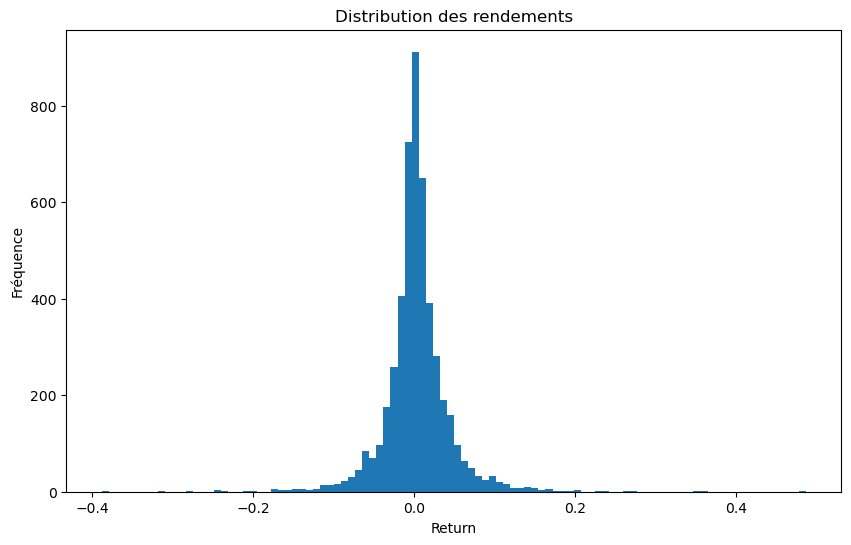

In [4]:
#Observation de la dispersion des rendements :
# Nous voulons observer asymetrie, dispersion, valeurs extrêmes

plt.figure(figsize=(10,6))

plt.hist(df["return"],bins=100)

plt.title("Distribution des rendements")

plt.xlabel("Return")

plt.ylabel("Fréquence")

plt.show()

### Interprétation

Les rendements journaliers sont majoritairement concentrés autour de zéro, ce qui montre que la plupart des variations quotidiennes restent limitées.  
Cependant, la présence de valeurs extrêmes positives et négatives confirme le caractère volatil du marché crypto.

Cette distribution n’est pas parfaitement normale et présente des queues épaisses.  
Cela justifie l’utilisation d’une target ajustée à la volatilité plutôt qu’un seuil fixe de décision.

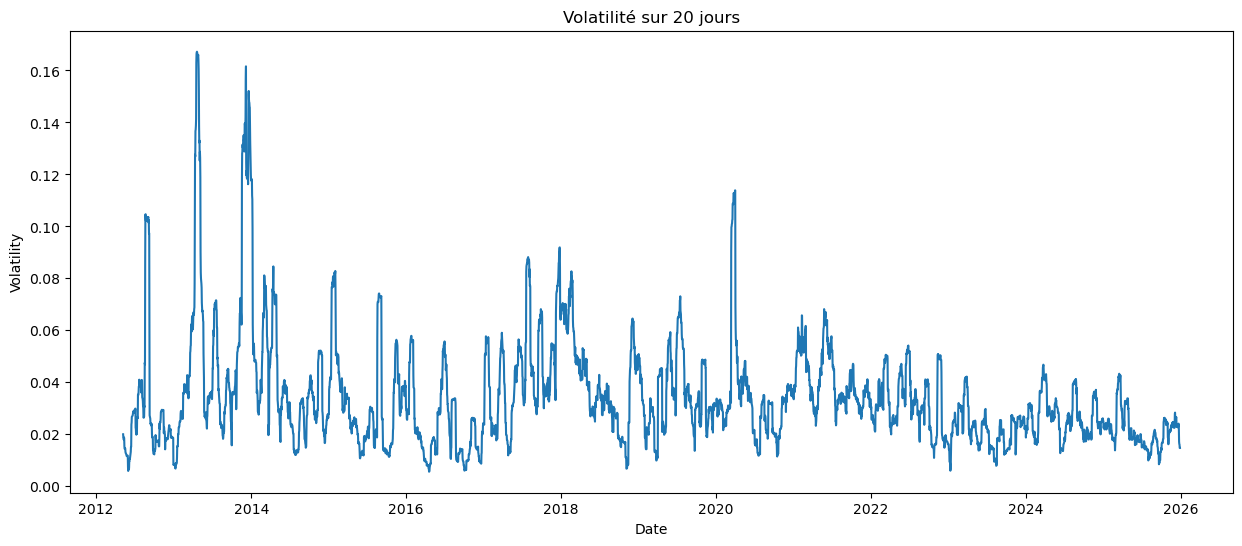

In [5]:
#volatilité
plt.figure(figsize=(15,6))

plt.plot(df["date"],df["volatility_20"])

plt.title("Volatilité sur 20 jours")

plt.xlabel("Date")

plt.ylabel("Volatility")

plt.show()

## Interprétation

Observations :

La volatilité n'est pas constante dans le temps.

Interprétation :

Le marché traverse des périodes :

- calmes
- instables
- fortement spéculatives

Conséquence :

Un seuil fixe pour BUY/SELL pourrait être inadapté.

Cela justifie notre approche :

Volatility Adjusted Signal

## Corrélations

Objectif :

Identifier les variables redondantes.

Pourquoi Spearman ?

- robuste aux outliers
- distributions non normales
- relations potentiellement non linéaires

In [6]:
corr = (df.select_dtypes(include=["number"]).drop(columns=["target"]).corr(method="spearman"))

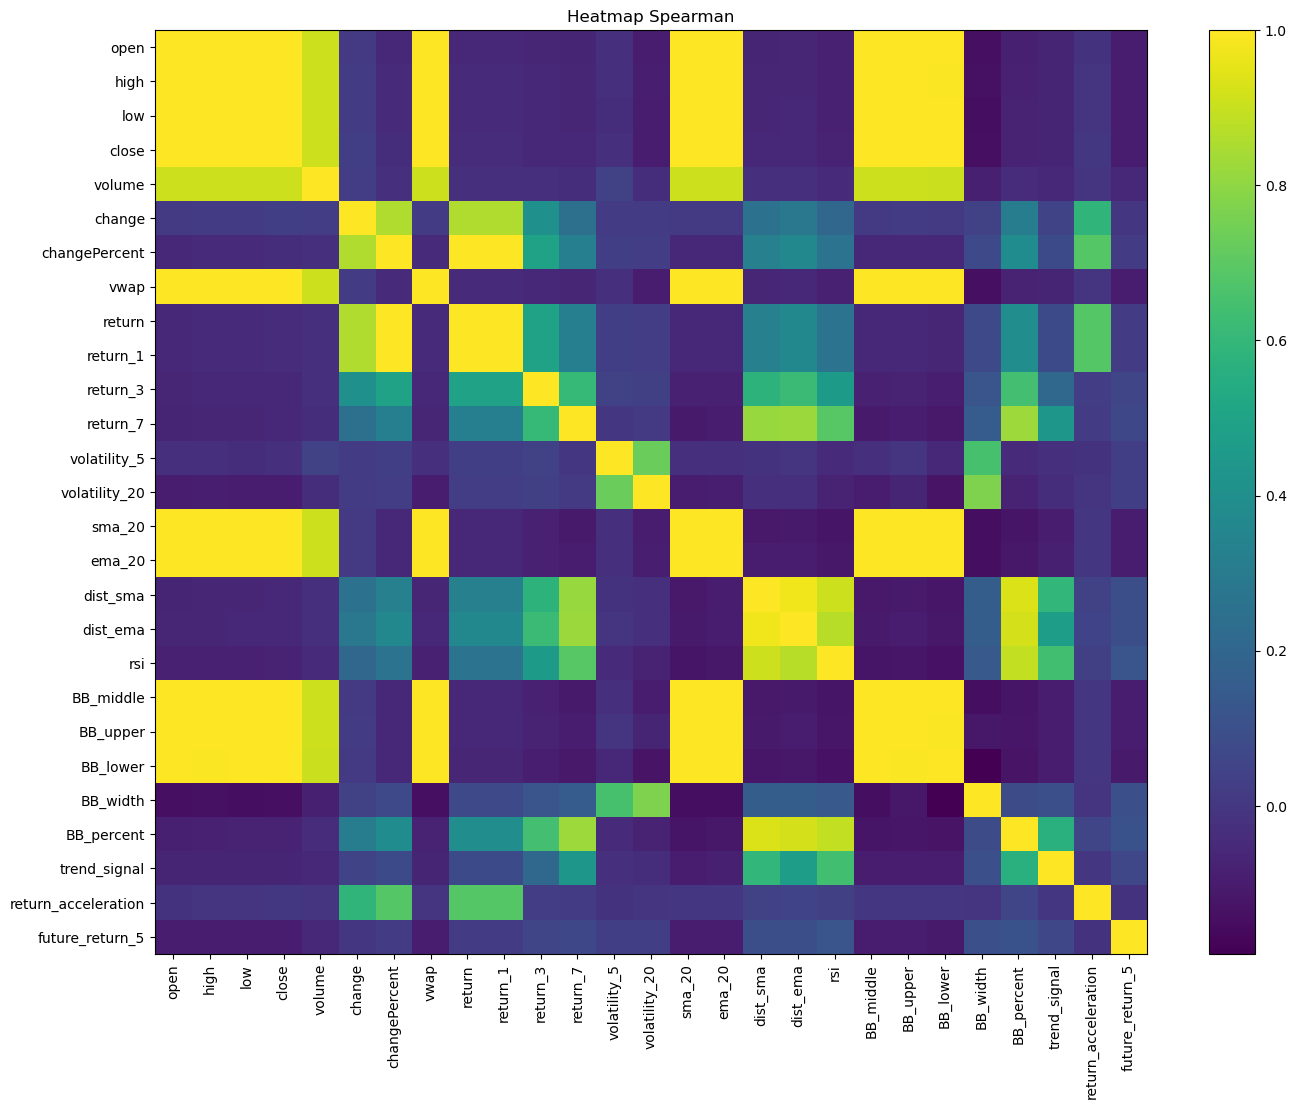

In [7]:
plt.figure(figsize=(16,12))

plt.imshow(corr,aspect="auto")

plt.colorbar()

plt.xticks(range(len(corr.columns)),corr.columns,rotation=90)

plt.yticks(range(len(corr.columns)),corr.columns)

plt.title("Heatmap Spearman")

plt.show()

## Interprétation

Observations :

Plusieurs groupes de variables présentent une très forte corrélation :

- open
- high
- low
- close
- vwap
- sma_20
- ema_20
- BB_middle
- BB_upper
- BB_lower

Interprétation :

Ces variables décrivent majoritairement la même information : le niveau général du prix.

Conserver simultanément toutes ces variables peut entraîner :

- redondance
- surapprentissage
- instabilité du modèle

Conséquence :

Une sélection sera nécessaire lors des étapes suivantes.

In [8]:
#Mutual information
# Cette étape nous permets d'identifier l'information apportée par une variable à la target, 
# independamment des relations linéaires

X = df.drop(columns=["target","future_return_5","date","symbol"])

y = df["target"]

In [9]:
mi_scores = mutual_info_classif(X,y)

mi = pd.Series(mi_scores,index=X.columns)

mi = mi.sort_values(ascending=False)

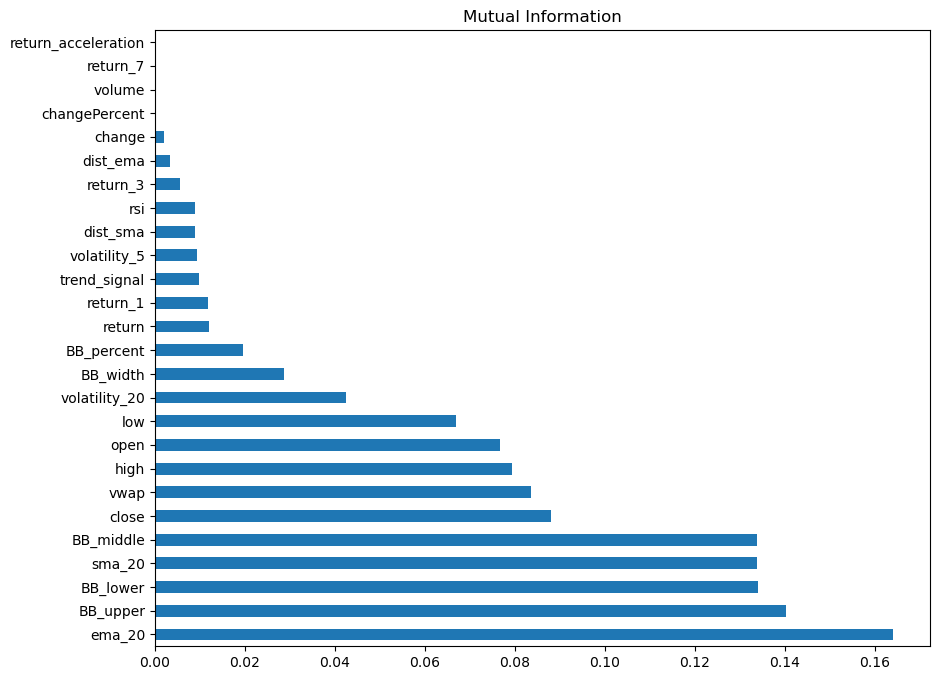

In [10]:
plt.figure(figsize=(10,8))

mi.plot(kind="barh")

plt.title("Mutual Information")
plt.show()

## Interprétation

Observations :

Certaines variables semblent apporter davantage d'information à la cible.

Interprétation :

Une variable fortement informative n'est pas automatiquement retenue.

Le choix final dépendra aussi :

- de la robustesse
- de la redondance
- de l'interprétabilité


Les variables liées au niveau du prix semblent apporter davantage d'information à la cible.

Interprétation :

Une forte importance statistique n'implique pas automatiquement qu'une variable doit être conservée.

Certaines variables importantes peuvent contenir une information similaire.

Conséquence :

Les résultats de Mutual Information devront être combinés avec l'analyse de multicolinéarité.

In [11]:
#Multicolinarité
# Nous observerons les relations fortement liées

X_vif = X.dropna()
vif = pd.DataFrame()

vif["Variable"] = X_vif.columns

vif["VIF"] = [variance_inflation_factor(X_vif.values,i)for i in range(X_vif.shape[1])]

c:\Users\romar\.conda\envs\DS2025-projet-Simu\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [12]:
vif.sort_values("VIF",ascending=False)

,Variable,VIF
0,open,inf
1,high,inf
2,low,inf
3,close,inf
5,change,inf
7,vwap,inf
9,return_1,inf
8,return,inf
21,BB_lower,inf
14,sma_20,inf


## Interprétation

Observations :

Certaines variables présentent une multicolinéarité élevée.

Interprétation :

Des variables très corrélées peuvent transmettre une information similaire.

Conséquence :

Une sélection finale pourra supprimer certaines variables redondantes afin d'améliorer :

- stabilité
- interprétabilité
- généralisation



Plusieurs variables présentent des VIF extrêmement élevés, voire infinis.

Interprétation :

Certaines variables sont presque entièrement expliquées par d'autres variables présentes dans le dataset.

Exemple :

- BB_middle ≈ sma_20
- BB_upper dépend directement de BB_middle
- open/high/low/close évoluent ensemble

Conséquence :

Une réduction du nombre de variables sera nécessaire afin :

- d'améliorer la stabilité du modèle
- de réduire la redondance
- d'améliorer l'interprétabilité

## Conclusion

Cette étape permet :

✓ comprendre le comportement général du marché

✓ identifier les variables redondantes

✓ mesurer l'information apportée par chaque variable

✓ préparer une sélection finale raisonnée

Les suppressions éventuelles de variables seront décidées à partir des analyses statistiques et des considérations métier.


Les analyses de corrélation et de multicolinéarité ont mis en évidence plusieurs variables potentiellement redondantes :

- open
- high
- low
- change
- BB_middle
- éventuellement vwap
- éventuellement BB_upper
- éventuellement BB_lower

Ces variables ne sont pas supprimées immédiatement.

Une validation expérimentale sera réalisée lors des étapes de modélisation afin de comparer :

- modèle avec toutes les variables
- modèle avec variables filtrées

La décision finale sera prise sur la base des performances obtenues.

In [13]:
import matplotlib.pyplot as plt

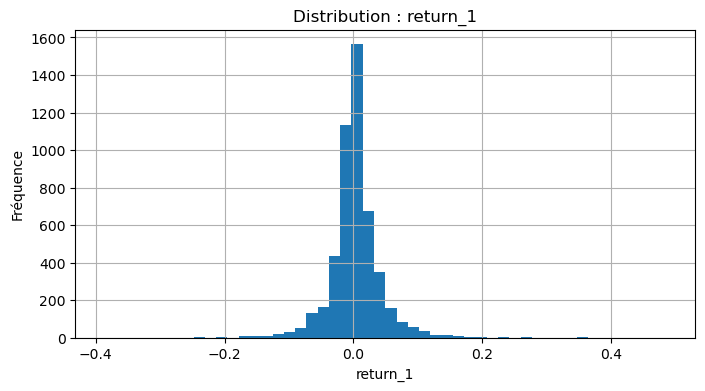

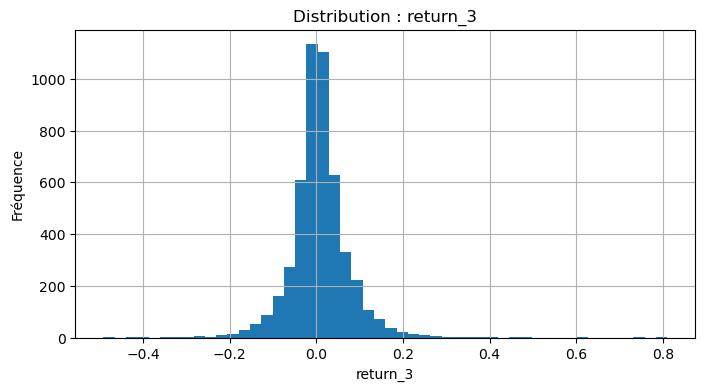

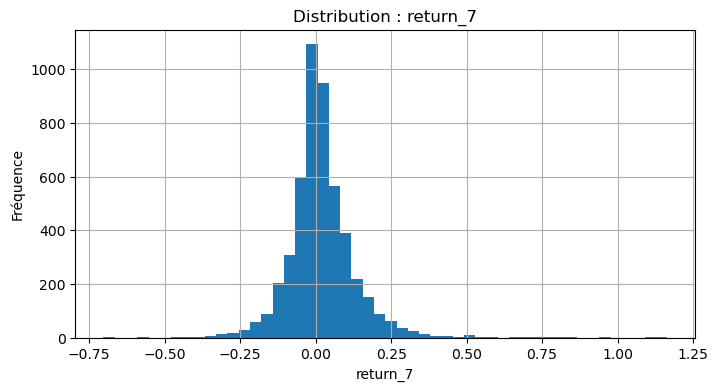

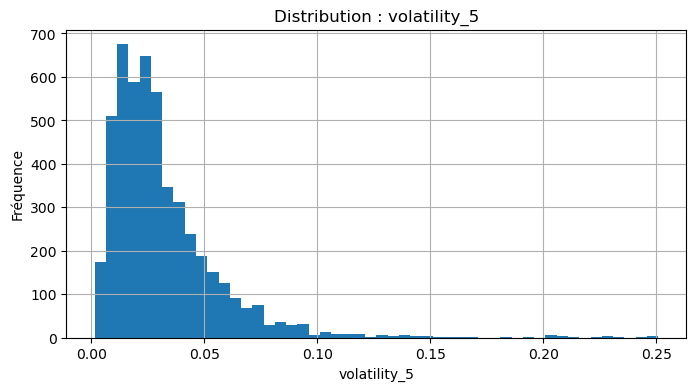

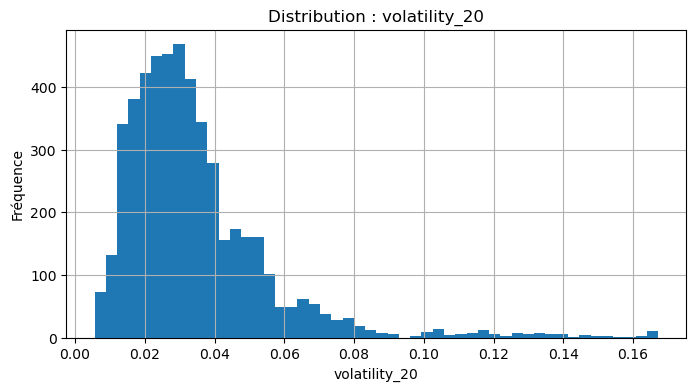

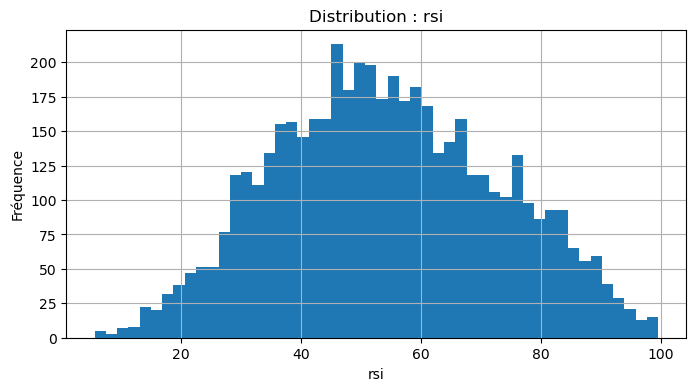

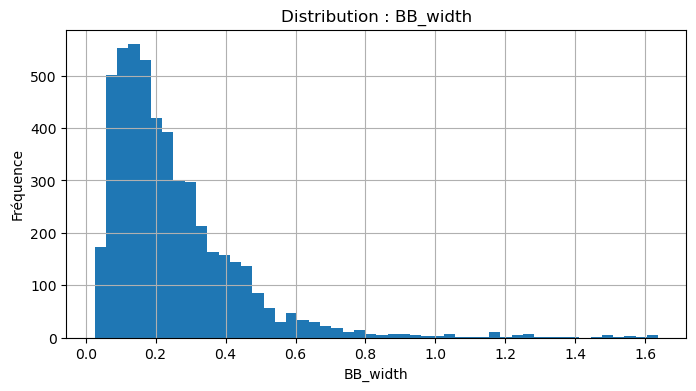

In [14]:
variables = [

    "return_1",
    "return_3",
    "return_7",

    "volatility_5",
    "volatility_20",

    "rsi",

    "BB_width"

]

for col in variables:

    plt.figure(figsize=(8,4))

    plt.hist(
        df[col],
        bins=50
    )

    plt.title(
        f"Distribution : {col}"
    )

    plt.xlabel(col)

    plt.ylabel("Fréquence")

    plt.grid()

    plt.show()

In [15]:
distribution_stats=[]

for col in variables:

    distribution_stats.append({

        "Variable":col,

        "Skewness":
        df[col].skew(),

        "Kurtosis":
        df[col].kurt()
    })

distribution_df=pd.DataFrame(
    distribution_stats
)

distribution_df

,Variable,Skewness,Kurtosis
0,return_1,0.368712,13.864162
1,return_3,0.843639,12.088877
2,return_7,1.439420,10.205905
3,volatility_5,3.141587,16.887024
4,volatility_20,2.392930,8.753856
5,rsi,0.099328,-0.616633
6,BB_width,2.633000,11.115523




Les distributions des rendements présentent une forte concentration autour de zéro avec des queues épaisses.

Les valeurs de kurtosis élevées montrent que des mouvements extrêmes apparaissent plus souvent qu'une distribution normale.

Ce comportement est classique pour les séries financières et reflète les épisodes de forte volatilité du marché BTC.



La volatilité présente une forte asymétrie positive.

Cela indique que les périodes de marché calme sont majoritaires, mais qu'elles sont ponctuées par des épisodes rares de très forte instabilité.



Le RSI présente une distribution relativement équilibrée.

Contrairement aux rendements bruts, cette variable est déjà transformée et bornée entre 0 et 100, ce qui réduit naturellement les valeurs extrêmes.

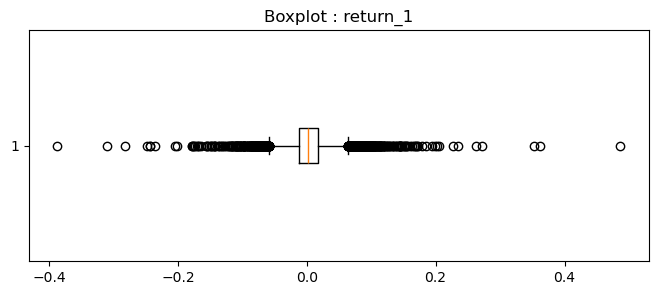

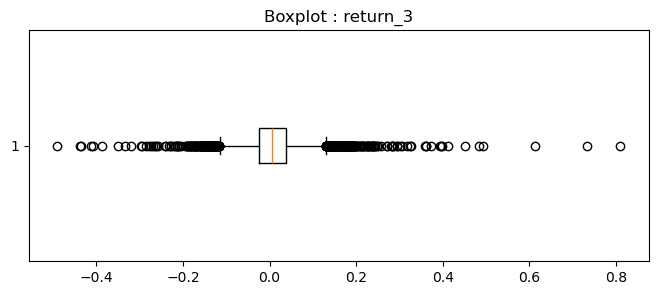

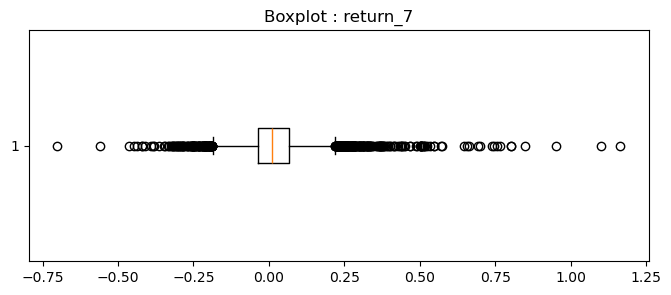

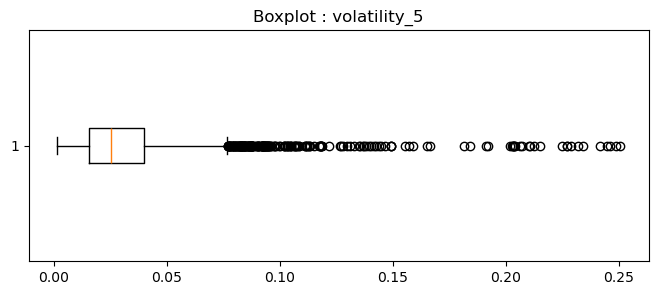

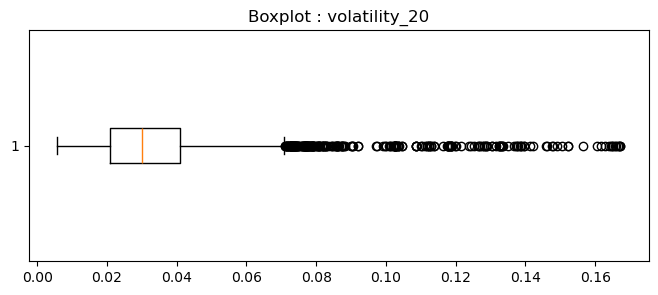

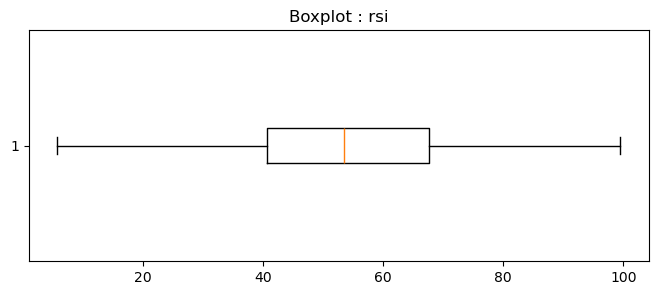

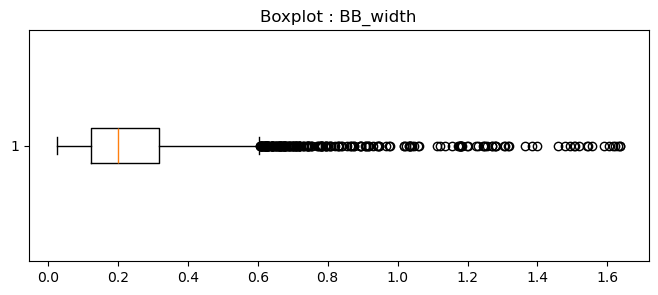

In [16]:
for col in variables:

    plt.figure(
        figsize=(8,3)
    )

    plt.boxplot(
        df[col],
        vert=False
    )

    plt.title(
        f"Boxplot : {col}"
    )

    plt.show()

In [17]:
outlier_results=[]

for col in variables:

    Q1=df[col].quantile(0.25)

    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower=Q1-(1.5*IQR)

    upper=Q3+(1.5*IQR)

    n_outliers=((df[col]<lower)|
                (df[col]>upper)).sum()

    outlier_results.append({

        "Variable":col,

        "Nb_outliers":n_outliers,

        "%_outliers":
        round(
            n_outliers/len(df)*100,
            2
        )
    })

outliers_df=pd.DataFrame(
    outlier_results
)

outliers_df

,Variable,Nb_outliers,%_outliers
0,return_1,493,9.91
1,return_3,366,7.36
2,return_7,336,6.75
3,volatility_5,217,4.36
4,volatility_20,248,4.98
5,rsi,0,0.00
6,BB_width,221,4.44



Des valeurs extrêmes ont été détectées sur plusieurs variables.

Cependant, dans le contexte des marchés financiers et particulièrement des cryptomonnaies, ces observations représentent souvent des événements réels du marché plutôt que des erreurs de mesure.

Les outliers ont donc été conservés afin d'éviter une perte d'information potentiellement utile au modèle.



En conclusion, 

Les données financières présentent souvent :

- asymétrie (skewness)
- queues épaisses (kurtosis élevée)
- présence d'outliers

L'objectif n'est pas nécessairement de supprimer tous les outliers.

Dans le cas des marchés financiers, certains mouvements extrêmes représentent des événements réels du marché et peuvent contenir une information importante.